# Módulo 2 — Sentimiento vs Volatilidad

**Proyecto:** Market Intelligence Copilot — Pipeline NLP de Volatilidad

¿El sentimiento de noticias del día `t` predice la **volatilidad** del día `t+1`? Y sobre
todo: ¿**FinBERT** (título / cuerpo) le gana al **baseline** (sentimiento propio de EODHD)?

Disciplina **Point-in-Time**: el target es *siempre* estrictamente futuro (t+1), nunca el
mismo día. La alineación vive en `src/sentiment/dataset.py`.

> Spoiler honesto: a nivel diario la señal es **débil** (predecir volatilidad diaria es
> difícil). Lo interesante es *qué* señal es la menos débil.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

_root = Path.cwd()
while not (_root / "src").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
from src.sentiment import dataset

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
ASSETS = ["WTI", "BRENT", "HENRY_HUB"]

df = dataset.build_supervised(roll=5)
df["abs_body"] = df["finbert_body_mean"].abs()   # intensidad del sentimiento
df["abs_eodhd"] = df["eodhd_mean"].abs()
print("Dataset supervisado:", df.shape)
print("Rango:", df["trading_day"].min().date(), "->", df["trading_day"].max().date())
df[["trading_day", "asset", "n_articles", "finbert_body_mean", "eodhd_mean",
    "target_abs_ret", "target_rvol"]].head()

Dataset supervisado: (4455, 17)
Rango: 2020-01-02 -> 2026-06-22


,trading_day,asset,n_articles,finbert_body_mean,eodhd_mean,target_abs_ret,target_rvol
0,2020-01-02 00:00:00+00:00,WTI,1,-0.103515,NaN,0.029478,0.014660
1,2020-01-02 00:00:00+00:00,BRENT,1,-0.103515,NaN,0.029827,0.017086
2,2020-01-02 00:00:00+00:00,HENRY_HUB,1,-0.103515,NaN,0.004866,0.121126
3,2020-01-07 00:00:00+00:00,HENRY_HUB,1,0.408020,0.999,0.037563,0.028518
4,2020-01-08 00:00:00+00:00,WTI,1,-0.103515,NaN,0.001510,0.028792


## 1. Verificación Point-in-Time

El target debe ser **estrictamente el día siguiente** (`target_date > trading_day`).

In [2]:
ok = (df.dropna(subset=["target_date"]).eval("target_date > trading_day")).all()
print("target siempre futuro (t+1, sin look-ahead):", bool(ok))

target siempre futuro (t+1, sin look-ahead): True


## 2. ¿Qué señal predice mejor la volatilidad de t+1?

Correlación de Spearman de cada señal de sentimiento(t) contra la volatilidad(t+1).
Dos targets: `|return|` (crudo) y `realized vol` (media móvil 5d, más suave).
Señales: direccionales (media), **intensidad** (|.|), **desacuerdo** (std) y **volumen**.

In [3]:
signals = ["n_articles", "finbert_title_mean", "finbert_body_mean", "finbert_body_mean_trusted",
           "eodhd_mean", "abs_body", "finbert_body_std", "body_pos_minus_neg_ratio"]

def corr_table(target):
    rows = {}
    for a in ASSETS:
        sub = df[df["asset"] == a]
        rows[a] = {s: sub[[s, target]].corr(method="spearman").iloc[0, 1] for s in signals}
    return pd.DataFrame(rows).round(3)

print("=== vs |return| (t+1) ===")
print(corr_table("target_abs_ret").to_string())
print("\n=== vs realized vol (t+1) ===")
print(corr_table("target_rvol").to_string())

=== vs |return| (t+1) ===
                             WTI  BRENT  HENRY_HUB
n_articles                 0.038  0.063      0.023
finbert_title_mean        -0.012  0.015     -0.005
finbert_body_mean         -0.004  0.028      0.006
finbert_body_mean_trusted -0.084 -0.076      0.099
eodhd_mean                -0.050 -0.057     -0.059
abs_body                   0.005 -0.035     -0.070
finbert_body_std          -0.018  0.006      0.098
body_pos_minus_neg_ratio   0.001  0.041      0.014

=== vs realized vol (t+1) ===
                             WTI  BRENT  HENRY_HUB
n_articles                 0.113  0.138     -0.051
finbert_title_mean         0.017  0.016     -0.065
finbert_body_mean          0.021  0.018     -0.018
finbert_body_mean_trusted -0.097 -0.045      0.004
eodhd_mean                -0.131 -0.090     -0.040
abs_body                  -0.039 -0.072      0.012
finbert_body_std           0.048  0.060      0.031
body_pos_minus_neg_ratio   0.037  0.029     -0.001


## 3. FinBERT vs baseline EODHD (la tesis)

Comparación directa contra realized vol. Barras por activo.

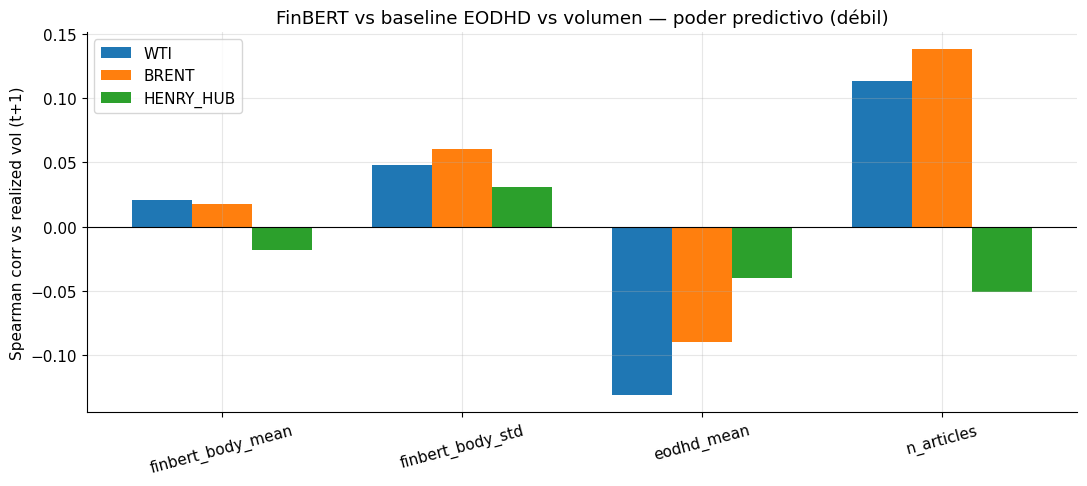

In [4]:
ct = corr_table("target_rvol")
comparar = ["finbert_body_mean", "finbert_body_std", "eodhd_mean", "n_articles"]
sub = ct.loc[comparar]
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(comparar)); w = 0.25
for i, a in enumerate(ASSETS):
    ax.bar(x + i*w, sub[a].values, w, label=a)
ax.set_xticks(x + w, comparar, rotation=15)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Spearman corr vs realized vol (t+1)")
ax.set_title("FinBERT vs baseline EODHD vs volumen — poder predictivo (débil)")
ax.legend()
fig.tight_layout()
plt.show()

## 4. El efecto más claro: volumen de noticias → volatilidad

La señal más consistente no es la *dirección* del sentimiento sino el **volumen**: más
noticias hoy → más volatilidad mañana. Se ve mejor agrupando por cuartil de `n_articles`.

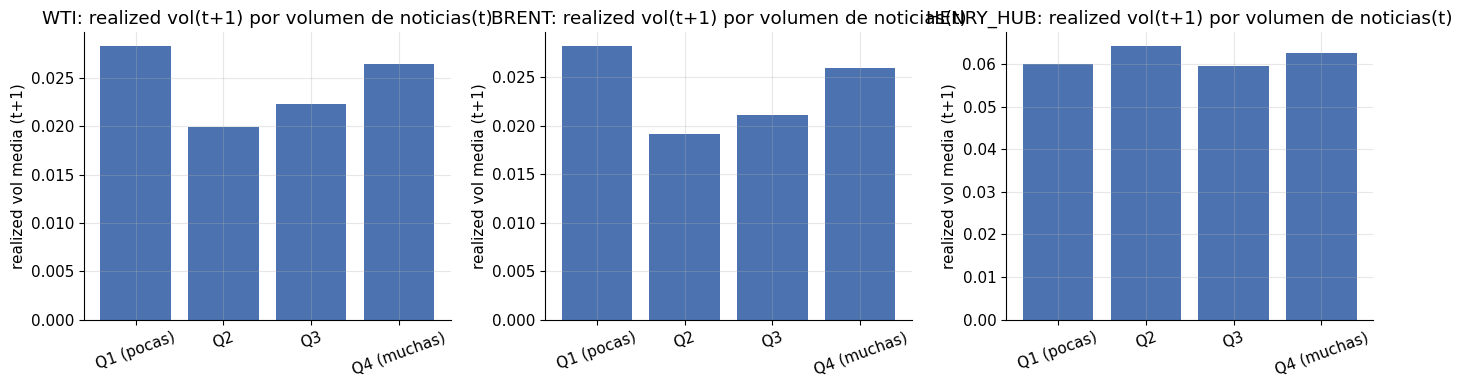

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, a in zip(axes, ASSETS):
    sub = df[df["asset"] == a].dropna(subset=["target_rvol"]).copy()
    sub["q"] = pd.qcut(sub["n_articles"].rank(method="first"), 4, labels=["Q1 (pocas)", "Q2", "Q3", "Q4 (muchas)"])
    m = sub.groupby("q", observed=True)["target_rvol"].mean()
    ax.bar(range(len(m)), m.values, color="#4c72b0")
    ax.set_xticks(range(len(m)), m.index, rotation=20)
    ax.set_title(f"{a}: realized vol(t+1) por volumen de noticias(t)")
    ax.set_ylabel("realized vol media (t+1)")
fig.tight_layout()
plt.show()

## 5. Sentimiento y volatilidad en el tiempo

Volumen de noticias mensual vs realized vol mensual (WTI). Co-mueven en los shocks
(COVID 2020, crisis energética 2022).

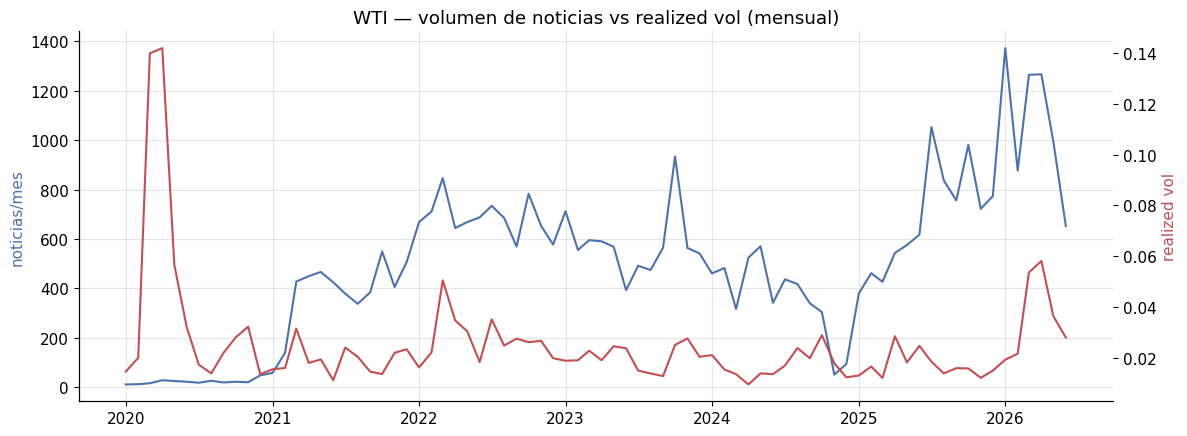

In [6]:
w = df[df["asset"] == "WTI"].set_index("trading_day").sort_index()
mv = w[["n_articles", "target_rvol"]].resample("MS").agg({"n_articles": "sum", "target_rvol": "mean"})
fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.plot(mv.index, mv["n_articles"], color="#4c72b0", label="noticias/mes")
ax1.set_ylabel("noticias/mes", color="#4c72b0")
ax2 = ax1.twinx()
ax2.plot(mv.index, mv["target_rvol"], color="#c44e52", label="realized vol")
ax2.set_ylabel("realized vol", color="#c44e52")
ax2.grid(False)
ax1.set_title("WTI — volumen de noticias vs realized vol (mensual)")
fig.tight_layout()
plt.show()

## Conclusiones (honestas)

- **La señal cruda es débil** a nivel diario (correlaciones ~0.05–0.14). Predecir volatilidad
  diaria desde sentimiento es genuinamente difícil — resultado esperado, no un fracaso.
- **Lo menos débil es el VOLUMEN de noticias** (más flujo → más volatilidad, ~+0.11/+0.14 en
  crudo) y el **sentimiento negativo** (EODHD polarity, ~−0.09/−0.13): ambos con signo
  económicamente sensato.
- **FinBERT direccional ≈ baseline** en este test lineal simple; no le gana claramente. Pero
  esto es una correlación cruda — el valor real de FinBERT se juega en un **modelo no-lineal
  con interacciones** (Módulo 3), no en un Spearman.
- **Realized vol es mejor target** que |return| crudo.
- **Henry Hub más ruidoso** (menos datos), como se anticipó.

→ El pipeline de sentimiento **funciona y es PiT-limpio**. La próxima pregunta (Módulo 3):
¿un modelo que combine **volumen + sentimiento + intensidad + interacciones** mejora sobre
estas señales sueltas?